In [ ]:
# Mount the Google Drive
from google.colab import drive
drive.mount('/content/drive')

# Import standard astronomy libraries
import matplotlib.pyplot as plt
import numpy as np
import glob
from astropy.io import fits
from astropy.utils.data import download_file
from astropy.visualization import astropy_mpl_style
from scipy.optimize import curve_fit

print("Libraries imported successfully")

Mounted at /content/drive
Libraries imported successfully


In [ ]:
# Enter the drive for our group
data_S3 = '/content/drive/MyDrive/S3 - ISYA/Hi-Res Spect Data/Reduced-Python-new/'

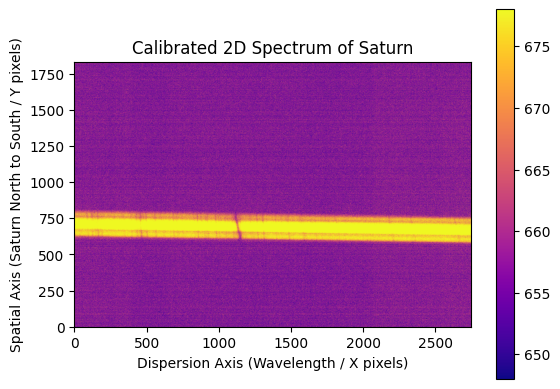

In [ ]:
# The final calibrated file
saturn_img_0 = fits.getdata(data_S3 + "saturn_stacked_calibrated_0.fits")
plt.imshow(saturn_img_0, vmin=np.percentile(saturn_img_0,5), vmax=np.percentile(saturn_img_0,95), origin = 'lower', cmap ='plasma')
plt.colorbar()
plt.title('Calibrated 2D Spectrum of Saturn')
plt.xlabel('Dispersion Axis (Wavelength / X pixels)')
plt.ylabel('Spatial Axis (Saturn North to South / Y pixels)')
plt.show()

In [ ]:
# Find yvals and xvals
yvals = np.argmax(saturn_img_0, axis=0)
xvals = np.arange(saturn_img_0.shape[1])

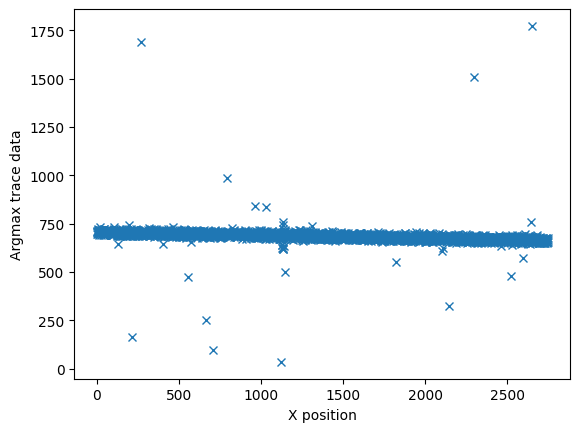

In [ ]:
plt.plot(xvals, yvals, "x")
plt.ylabel("Argmax trace data")
plt.xlabel("X position");

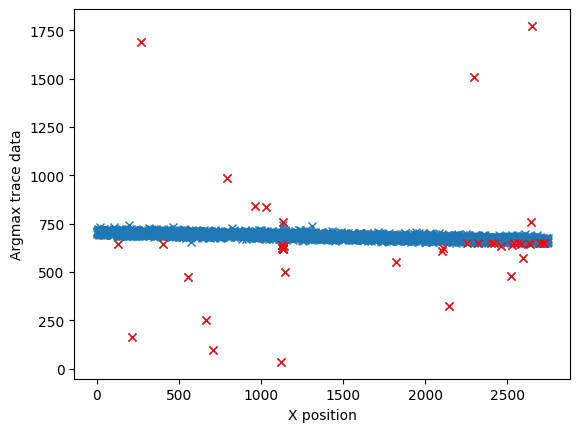

In [ ]:
# Get rid of bad pixels
bad_pixels = (yvals < 650) | (yvals > 750)
plt.plot(xvals, yvals, "x")
plt.plot(xvals[bad_pixels], yvals[bad_pixels], "rx")
plt.ylabel("Argmax trace data")
plt.xlabel("X position");

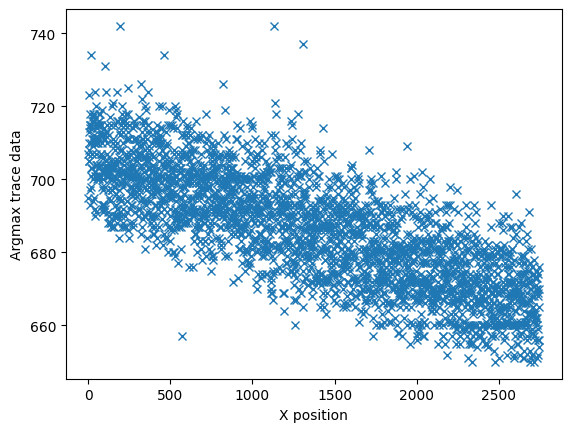

In [ ]:
plt.plot(xvals[~bad_pixels], yvals[~bad_pixels], "x")
plt.ylabel("Argmax trace data")
plt.xlabel("X position");

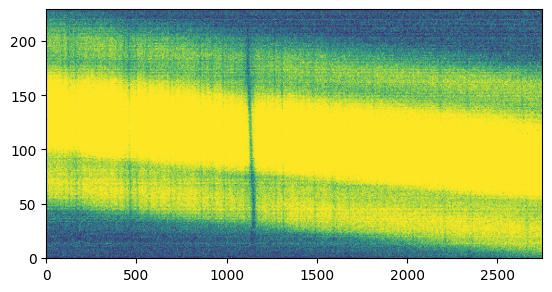

In [ ]:
plt.imshow(saturn_img_0[580:810, :], vmin=np.percentile(saturn_img_0,5), vmax=np.percentile(saturn_img_0,95), origin = 'lower')
plt.gca().set_aspect(6)

In [ ]:
# we use a cutout around the traced line
yaxis = np.repeat(np.arange(580, 810)[:, None], saturn_img_0.shape[1], axis=1)
background = np.median(saturn_img_0)
# moment 1 is the data-weighted average of the Y-axis coordinates
weighted_yaxis_values = np.average(
    yaxis, axis=0, weights=saturn_img_0[580:810, :] - background)

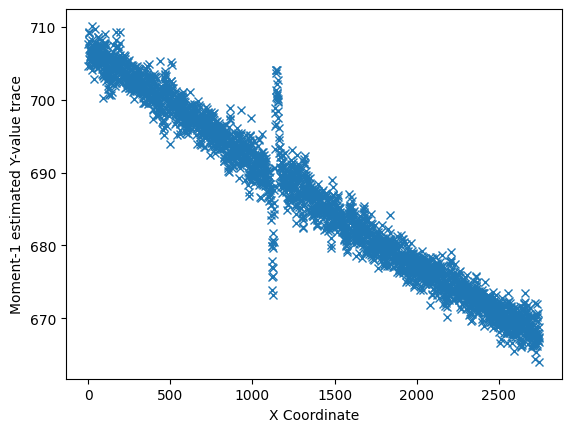

In [ ]:
plt.plot(xvals, weighted_yaxis_values, "x")
plt.xlabel("X Coordinate")
plt.ylabel("Moment-1 estimated Y-value trace");

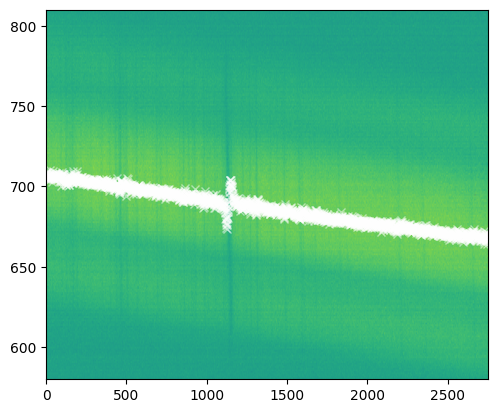

In [ ]:
# we need to use the 'extent' keyword to have the axes correctly labeled
plt.imshow(saturn_img_0[580:810, :], extent=[0, saturn_img_0.shape[1], 580, 810], origin = 'lower')
plt.gca().set_aspect(10)  # we stretch the image out by 10x in the y-direction
plt.plot(xvals, weighted_yaxis_values, "wx", alpha=0.5)
plt.axis((0, 2748, 580, 810));

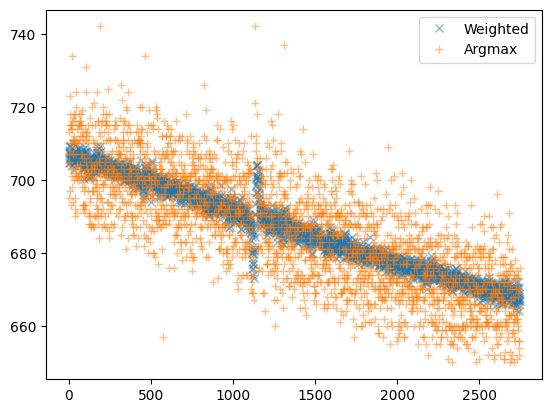

In [ ]:
plt.plot(xvals, weighted_yaxis_values, "x", label="Weighted", alpha=0.5)
plt.plot(xvals[~bad_pixels], yvals[~bad_pixels], "+", label="Argmax", alpha=0.5)
plt.legend(loc="best");

In [ ]:
bad_moments = (weighted_yaxis_values < 580) | (weighted_yaxis_values > 810)

#Fit The Trace Profile

In [ ]:
from astropy.modeling.polynomial import Polynomial1D
from astropy.modeling.fitting import LinearLSQFitter

In [ ]:
# We fit a 2nd-order polynomial
polymodel = Polynomial1D(degree=2)
linfitter = LinearLSQFitter()
fitted_polymodel = linfitter(
    polymodel, xvals[~bad_moments], weighted_yaxis_values[~bad_moments]
)

In [ ]:
fitted_polymodel

<Polynomial1D(2, c0=707.39425507, c1=-0.01638216, c2=0.00000068)>

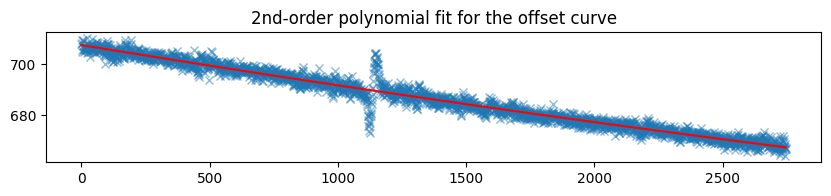

In [ ]:
fig = plt.figure(figsize=(10, 10))
plt.gca().set_aspect(10)
plt.title('2nd-order polynomial fit for the offset curve')
plt.plot(xvals[~bad_moments], weighted_yaxis_values[~bad_moments], "x", alpha=0.5)
plt.plot(xvals, fitted_polymodel(xvals), color="r");

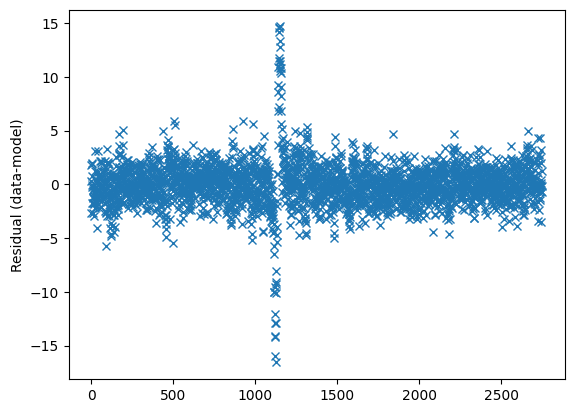

In [ ]:
plt.plot(
    xvals[~bad_moments],
    weighted_yaxis_values[~bad_moments] - fitted_polymodel(xvals[~bad_moments]),
    "x",
)
plt.ylabel("Residual (data-model)");

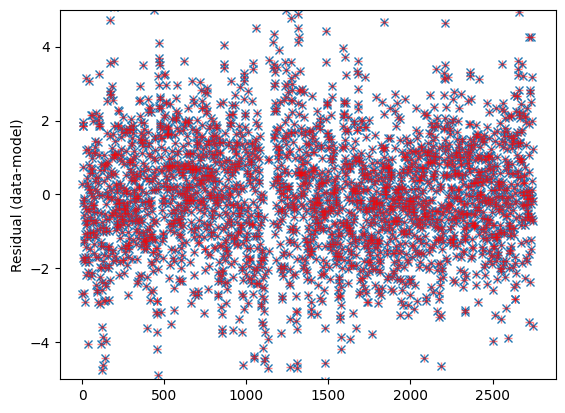

In [ ]:
plt.plot(
    xvals[~bad_moments] ,
    weighted_yaxis_values[~bad_moments]
    - fitted_polymodel(xvals[~bad_moments]),
    "x",
)
plt.plot(
    xvals[~bad_moments],
    weighted_yaxis_values[~bad_moments]
    - fitted_polymodel(xvals[~bad_moments]),
    "r+",
    alpha=0.5,
)
plt.ylim(-5, 5)
plt.ylabel("Residual (data-model)");

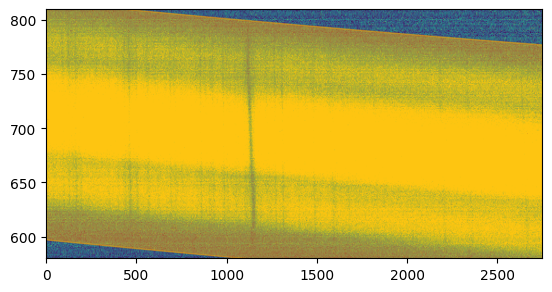

In [ ]:
plt.imshow(saturn_img_0[580:810, :], extent=[0, saturn_img_0.shape[1], 580, 810], vmin=np.percentile(saturn_img_0,5), vmax=np.percentile(saturn_img_0,95), origin = 'lower')
plt.gca().set_aspect(6)
plt.fill_between(
    xvals,
    fitted_polymodel(xvals) - 110,
    fitted_polymodel(xvals) + 110,
    color="orange",
    alpha=0.5,
)
plt.axis((0, 2748, 580, 810));

In [ ]:
# start by taking +/- 95 pixels
npixels_to_cut = 110
trace_center = fitted_polymodel(xvals)
cutouts = np.array(
    [
        saturn_img_0[int(yval) - npixels_to_cut : int(yval) + npixels_to_cut, ii]
        for yval, ii in zip(trace_center, xvals)
    ]
).T
cutouts.shape

(220, 2748)

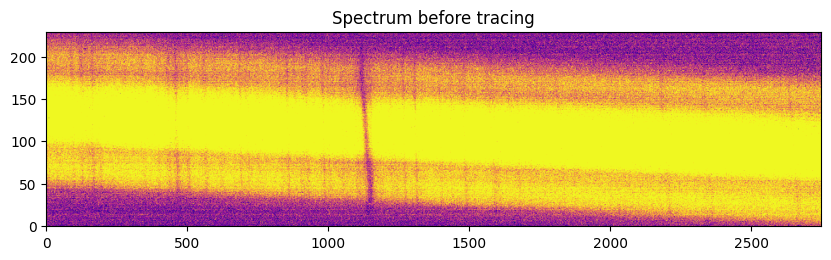

In [ ]:
fig = plt.figure(figsize=(10, 10))
plt.imshow(saturn_img_0[580:810, :], vmin=np.percentile(saturn_img_0,5), vmax=np.percentile(saturn_img_0,95), origin = 'lower', cmap ='plasma')
plt.title("Spectrum before tracing")
plt.gca().set_aspect(3)

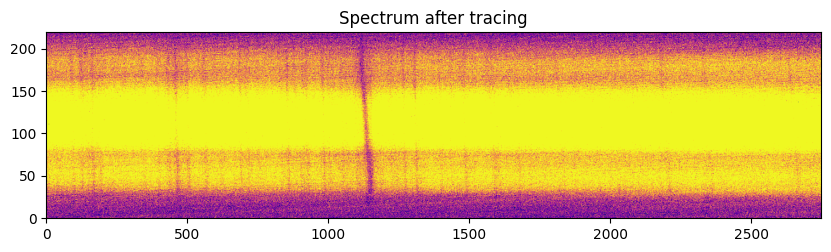

In [ ]:
fig = plt.figure(figsize=(10, 10))
plt.imshow(cutouts, vmin=np.percentile(saturn_img_0,5), vmax=np.percentile(saturn_img_0,95), origin = 'lower', cmap ='plasma')
plt.title("Spectrum after tracing")
plt.gca().set_aspect(3)

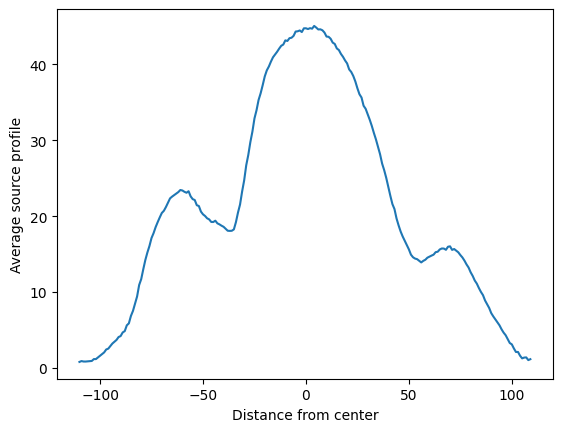

In [ ]:
mean_trace_profile = (cutouts.T - background).mean(axis=0)
npixels_to_cut = 110
trace_profile_xaxis = np.arange(-npixels_to_cut, npixels_to_cut)
plt.plot(trace_profile_xaxis, mean_trace_profile)
plt.xlabel("Distance from center")
plt.ylabel("Average source profile");

In [ ]:
from astropy.modeling.models import Gaussian1D
from astropy.modeling.fitting import LevMarLSQFitter, TRFLSQFitter

# Linear Fit
lmfitter = LevMarLSQFitter()

guess = Gaussian1D(amplitude=mean_trace_profile.max(), mean=0, stddev=5)
fitted_trace_profile = lmfitter(
    model=guess, x=trace_profile_xaxis, y=mean_trace_profile
)
model_trace_profile = fitted_trace_profile(trace_profile_xaxis)
fitted_trace_profile

# Non-Linear Fit with 3 Peaks
trfiltter = TRFLSQFitter()

# Define the three peaks with reasonable initial parameters
g1 = Gaussian1D(amplitude=mean_trace_profile.max() * 0.4, mean=-65, stddev=10)
g2 = Gaussian1D(amplitude=mean_trace_profile.max(), mean=0, stddev=5)
g3 = Gaussian1D(amplitude=mean_trace_profile.max() * 0.4, mean=65, stddev=10)

guess_non_linear = g1 + g2 + g3
fitted_trace_profile_non_linear = trfiltter(
    model=guess_non_linear, x=trace_profile_xaxis, y=mean_trace_profile
)
model_trace_profile_non_linear =  fitted_trace_profile_non_linear(trace_profile_xaxis)
fitted_trace_profile_non_linear

<CompoundModel(amplitude_0=19.11534469, mean_0=-65.86641576, stddev_0=12.81453821, amplitude_1=46.26984305, mean_1=3.30317251, stddev_1=31.11710977, amplitude_2=11.67734156, mean_2=75.72432459, stddev_2=13.01641885)>

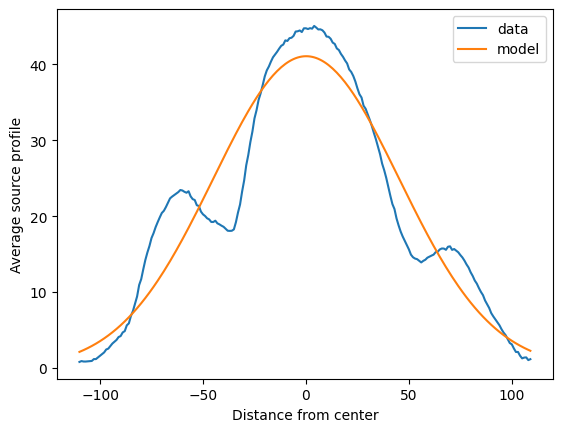

In [ ]:
# Plot the linear model
plt.plot(trace_profile_xaxis, mean_trace_profile, label="data")
plt.plot(trace_profile_xaxis, model_trace_profile, label="model")
plt.legend(loc="best")
plt.xlabel("Distance from center")
plt.ylabel("Average source profile");

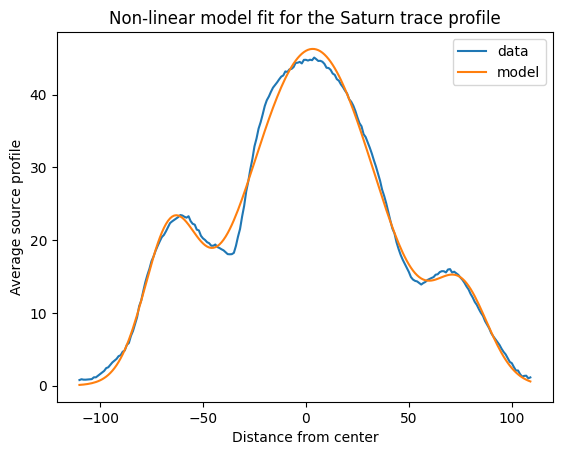

In [ ]:
# Plot the non-linear model
plt.plot(trace_profile_xaxis, mean_trace_profile, label="data")
plt.plot(trace_profile_xaxis, model_trace_profile_non_linear, label="model")
plt.legend(loc="best")
plt.title('Non-linear model fit for the Saturn trace profile')
plt.xlabel("Distance from center")
plt.ylabel("Average source profile");

In [ ]:
# Measure the slope of the slanted line


In [ ]:
#Divide the spectrum into three regions
saturn = cutouts[75:155, ::]
lower_ring = cutouts[30:60, ::]
upper_ring = cutouts[150:174, ::]


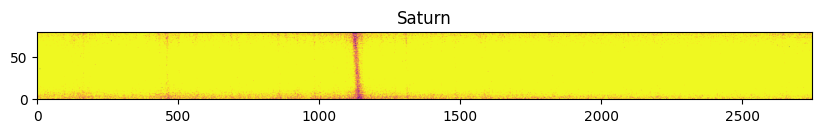

In [ ]:
fig = plt.figure(figsize=(10, 10))
plt.imshow(saturn, vmin=np.percentile(saturn_img_0,5), vmax=np.percentile(saturn_img_0,95), origin = 'lower', cmap ='plasma')
plt.title("Saturn")
plt.gca().set_aspect(3)

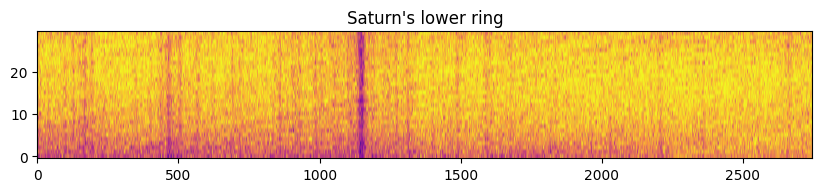

In [ ]:
fig = plt.figure(figsize=(10, 7))
plt.imshow(lower_ring, vmin=np.percentile(saturn_img_0,5), vmax=np.percentile(saturn_img_0,96), origin = 'lower', cmap ='plasma')
plt.title("Saturn's lower ring")
plt.gca().set_aspect(15)

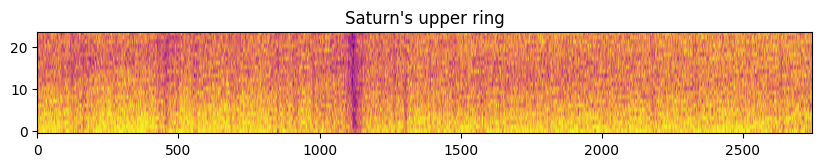

In [ ]:
fig = plt.figure(figsize=(10, 7))
plt.imshow(upper_ring, vmin=np.percentile(saturn_img_0,5), vmax=np.percentile(saturn_img_0,96), origin = 'lower', cmap ='plasma')
plt.title("Saturn's upper ring")
plt.gca().set_aspect(15)

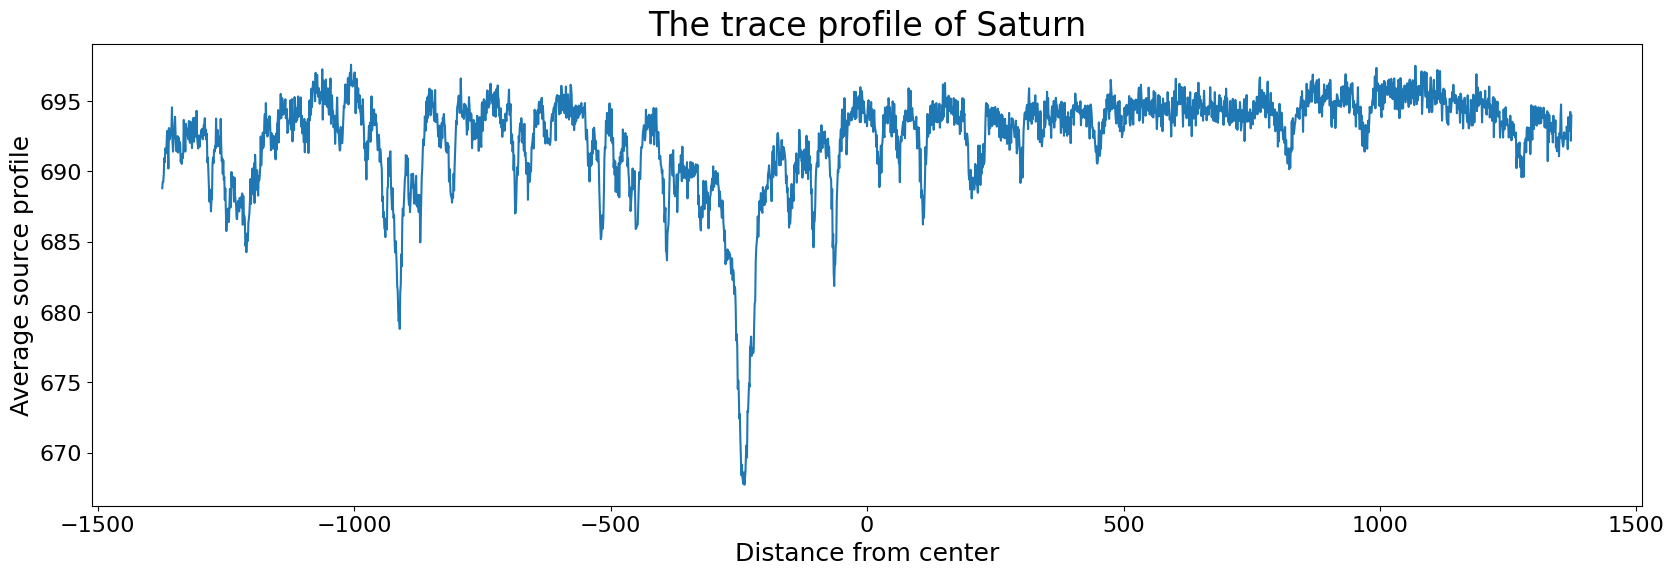

In [ ]:
fig = plt.figure(figsize=(20, 6))
saturn_mean_trace_profile = (saturn).mean(axis=0)
npixels_to_cut = len(saturn_mean_trace_profile) / 2
saturn_trace_profile_xaxis = np.arange(-npixels_to_cut, npixels_to_cut)
plt.plot(saturn_trace_profile_xaxis, saturn_mean_trace_profile)
plt.title('The trace profile of Saturn', fontsize = 24)
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)
plt.xlabel("Distance from center", fontsize = 18)
plt.ylabel("Average source profile", fontsize = 18);

In [ ]:
# Re-calculate the trace average spectrum using the correct weights slice matching 'saturn'
# saturn = cutouts[75:155, ::] which has 80 spatial pixels
saturn_weights = mean_trace_profile[75:155]

trace_avg_spectrum = np.array([
    np.average(
        saturn[:, ii],
        weights=saturn_weights,
        axis=0
    )
    for ii in xvals
])

In [ ]:
model_weights = model_trace_profile[75:155]

gaussian_trace_avg_spectrum = np.array(
    [
        np.average(
            saturn[:, ii],
            weights=model_weights,
        )
        for yval, ii in zip(trace_center, xvals)
    ]
)

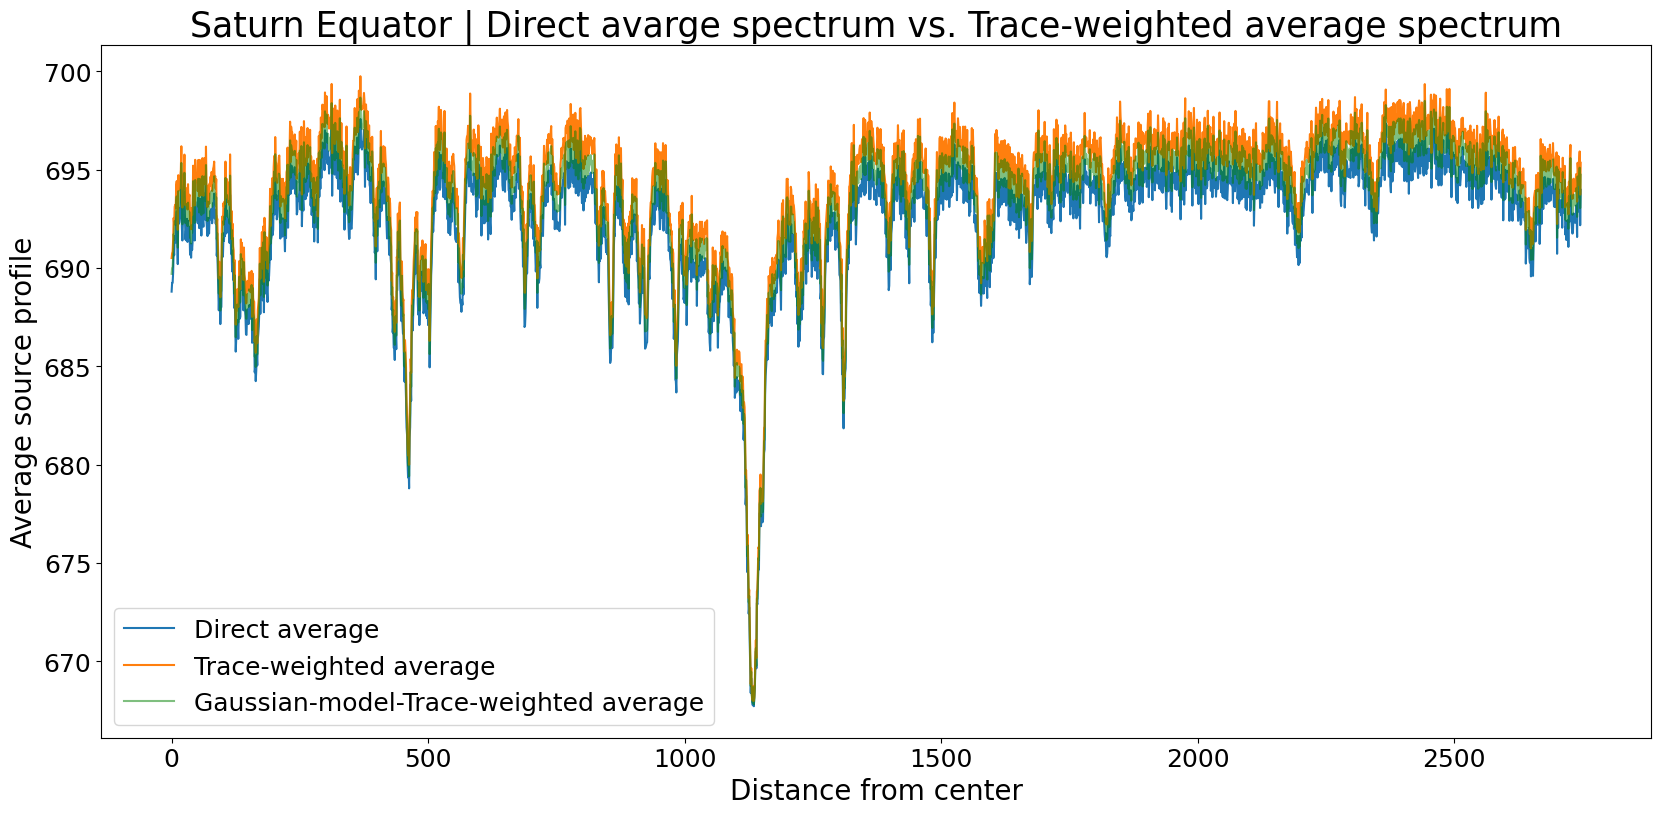

In [ ]:
fig = plt.figure(figsize=(20, 9))
plt.plot(saturn_mean_trace_profile, label="Direct average")
plt.plot(trace_avg_spectrum, label="Trace-weighted average")
plt.plot(
    gaussian_trace_avg_spectrum,
    label="Gaussian-model-Trace-weighted average",
    alpha=0.5,
    linewidth=1.5,
    color="green",
)
plt.legend(loc="best", fontsize = 18);
plt.xticks(fontsize=18)
plt.yticks(fontsize=18)
plt.xlabel("Distance from center", fontsize = 20)
plt.ylabel("Average source profile", fontsize = 20)
plt.title('Saturn Equator | Direct avarge spectrum vs. Trace-weighted average spectrum', fontsize = 25);

In [ ]:
print(min(saturn_mean_trace_profile))
#extract the x position
print(np.argmin(saturn_mean_trace_profile))

667.725
1135


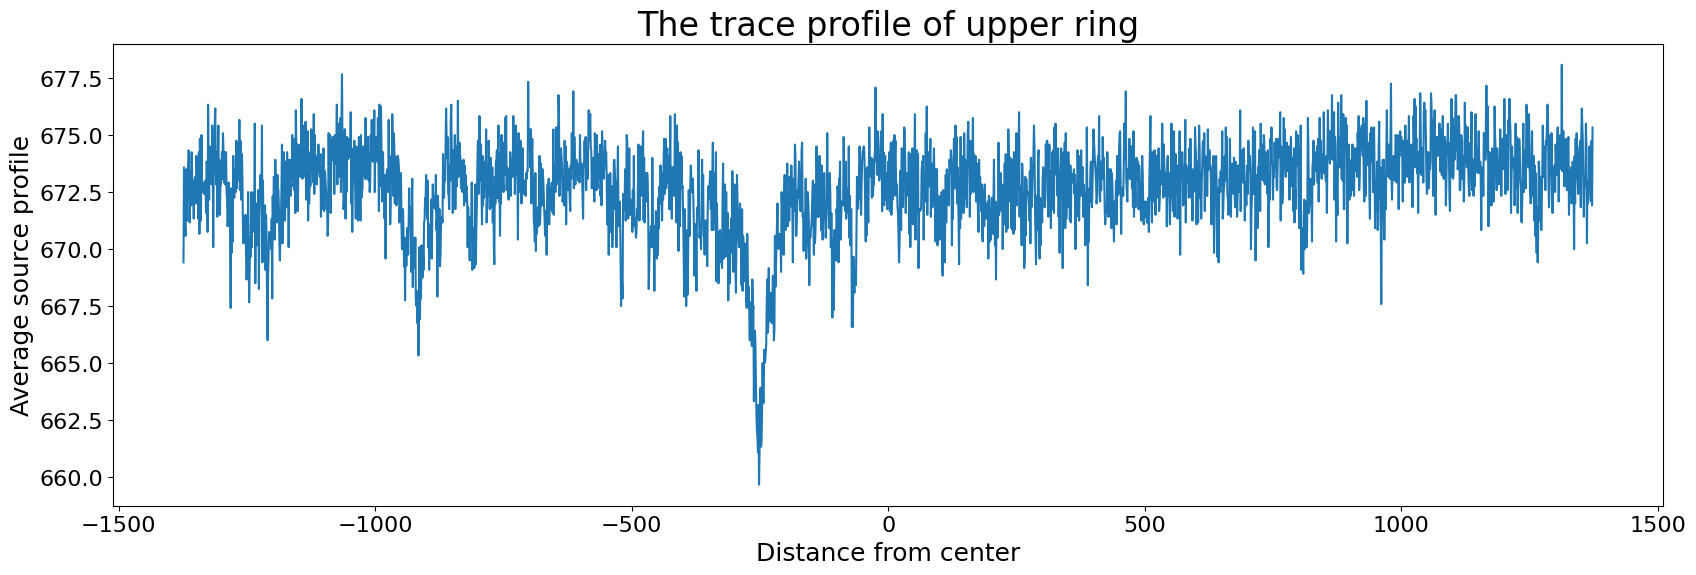

In [ ]:
fig = plt.figure(figsize=(20, 6))
upper_ring_mean_trace_profile = (upper_ring).mean(axis=0)
npixels_to_cut = len(upper_ring_mean_trace_profile) / 2
upper_ring_trace_profile_xaxis = np.arange(-npixels_to_cut, npixels_to_cut)
plt.plot(upper_ring_trace_profile_xaxis, upper_ring_mean_trace_profile)
plt.title('The trace profile of upper ring', fontsize = 24)
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)
plt.xlabel("Distance from center", fontsize = 18 )
plt.ylabel("Average source profile", fontsize = 18);

In [ ]:
print(min(upper_ring_mean_trace_profile))
#extract the x position
print(np.argmin(upper_ring_mean_trace_profile))

659.6666666666666
1122


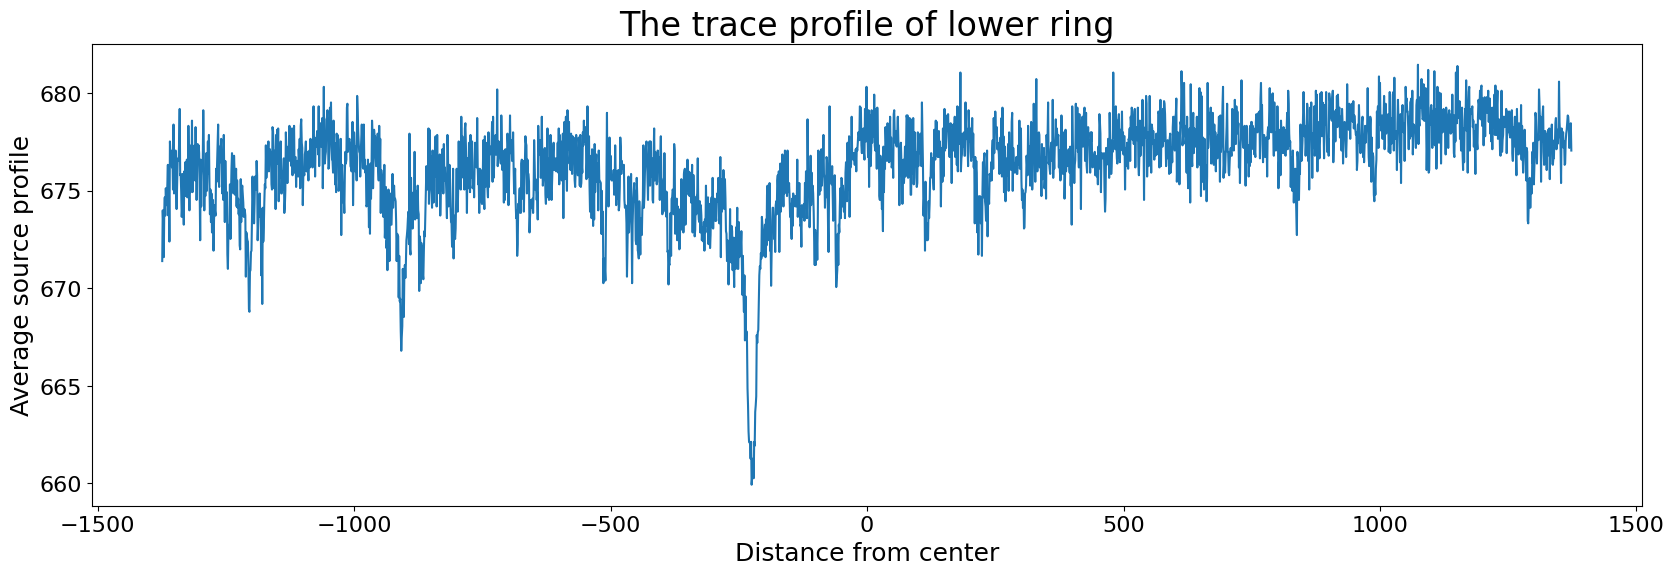

In [ ]:
fig = plt.figure(figsize=(20, 6))
lower_ring_mean_trace_profile = (lower_ring).mean(axis=0)
npixels_to_cut = len(lower_ring_mean_trace_profile) / 2
lower_ring_trace_profile_xaxis = np.arange(-npixels_to_cut, npixels_to_cut)
plt.plot(lower_ring_trace_profile_xaxis, lower_ring_mean_trace_profile)
plt.title('The trace profile of lower ring', fontsize = 24)
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)
plt.xlabel("Distance from center", fontsize = 18 )
plt.ylabel("Average source profile", fontsize = 18);

In [ ]:
print(min(lower_ring_mean_trace_profile))
#extract the x position
print(np.argmin(lower_ring_mean_trace_profile))

659.9333333333333
1149


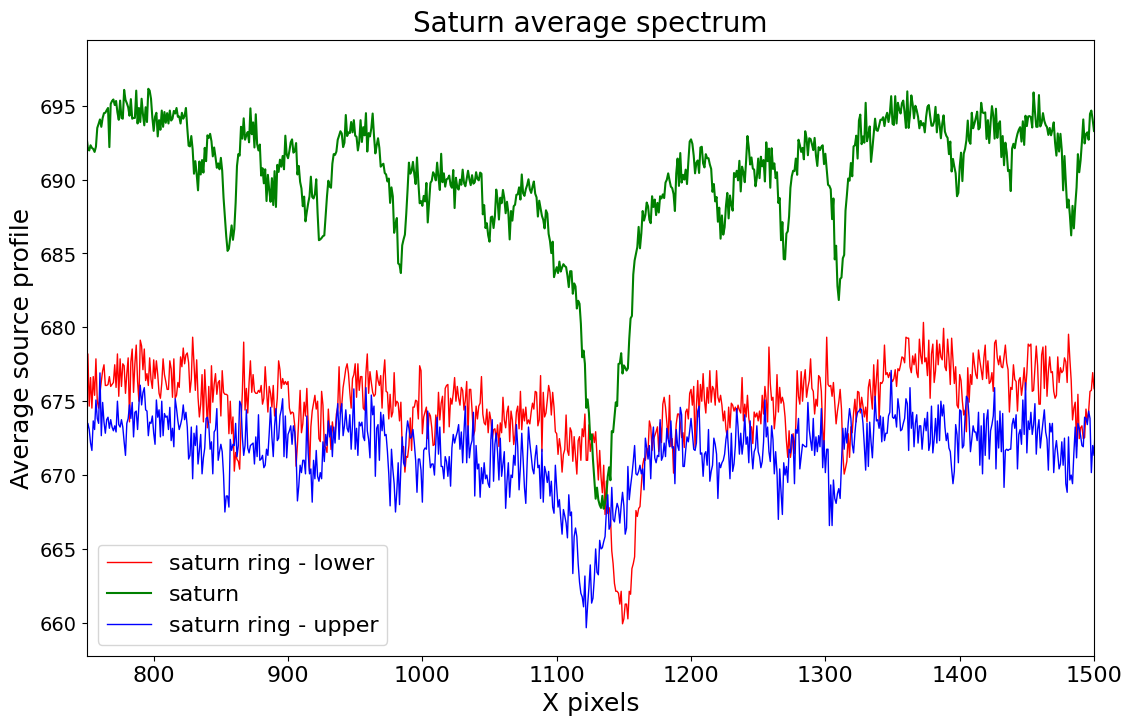

In [ ]:
fig = plt.figure(figsize=(13, 8))
saturn_average_spectrum = (saturn).mean(axis=0)
lower_ring_average_spectrum = (lower_ring).mean(axis=0)
upper_ring_average_spectrum = (upper_ring).mean(axis=0)
plt.title('Saturn average spectrum', fontsize = 20)
plt.plot(lower_ring_average_spectrum, color = 'red', label = 'saturn ring - lower', linewidth=1.0)
plt.plot(saturn_average_spectrum, color = 'green', label = 'saturn', linewidth=1.5)
plt.plot(upper_ring_average_spectrum, color = 'blue', label = 'saturn ring - upper', linewidth=1.0)
plt.legend(fontsize=16)
plt.xticks(fontsize=16)
plt.yticks(fontsize=14)
plt.xlabel("X pixels", fontsize=18)
plt.xlim([750, 1500])

plt.ylabel("Average source profile", fontsize=18);

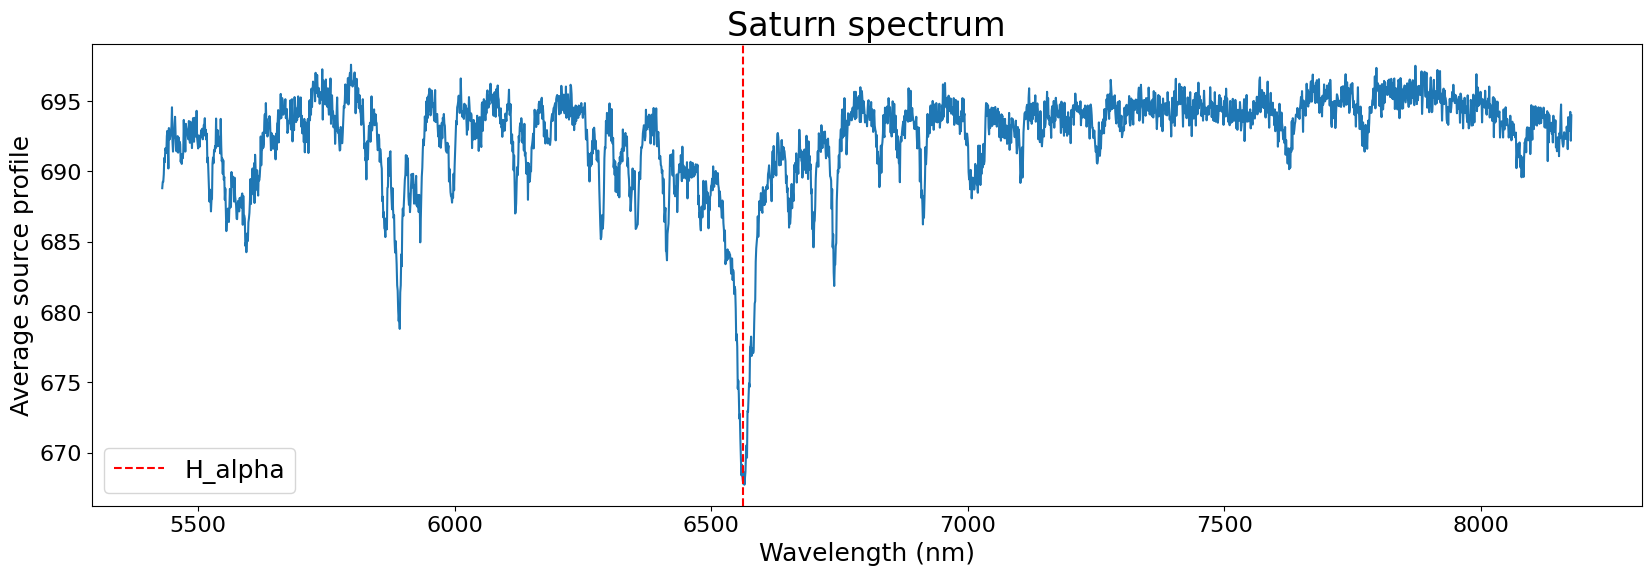

In [ ]:
fig = plt.figure(figsize=(20, 6))
saturn_mean_trace_profile = (saturn).mean(axis=0)
npixels_to_cut = len(saturn_mean_trace_profile)
saturn_trace_profile_xaxis = np.arange(6562.8 - 1133, 6562.8 - 1133 + npixels_to_cut)
plt.plot(saturn_trace_profile_xaxis, saturn_mean_trace_profile)
plt.title('Saturn spectrum', fontsize = 24)
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)
plt.xlabel("Wavelength (nm)", fontsize = 18)
plt.axvline(x=6562.8, color='r', linestyle='--', label = 'H_alpha')
plt.legend(fontsize=18)
plt.ylabel("Average source profile", fontsize = 18);

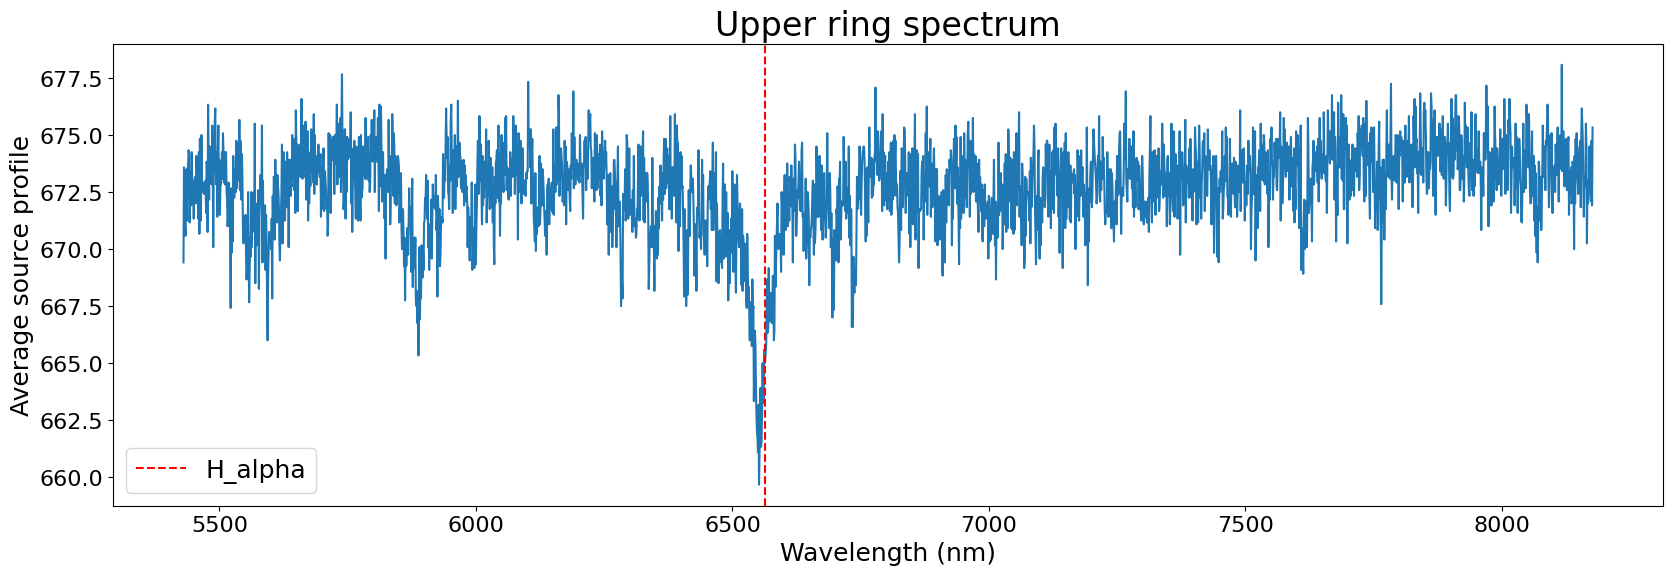

In [ ]:
fig = plt.figure(figsize=(20, 6))
upper_ring_mean_trace_profile = (upper_ring).mean(axis=0)
npixels_to_cut = len(upper_ring_mean_trace_profile)
upper_ring_trace_profile_xaxis =  np.arange(6562.8 - 1133, 6562.8 - 1133 + npixels_to_cut)
plt.plot(upper_ring_trace_profile_xaxis, upper_ring_mean_trace_profile)
plt.title('Upper ring spectrum', fontsize = 24)
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)
plt.axvline(x=6562.8, color='r', linestyle='--', label = 'H_alpha')
plt.legend(fontsize=18)
plt.xlabel("Wavelength (nm)", fontsize = 18 )
plt.ylabel("Average source profile", fontsize = 18);

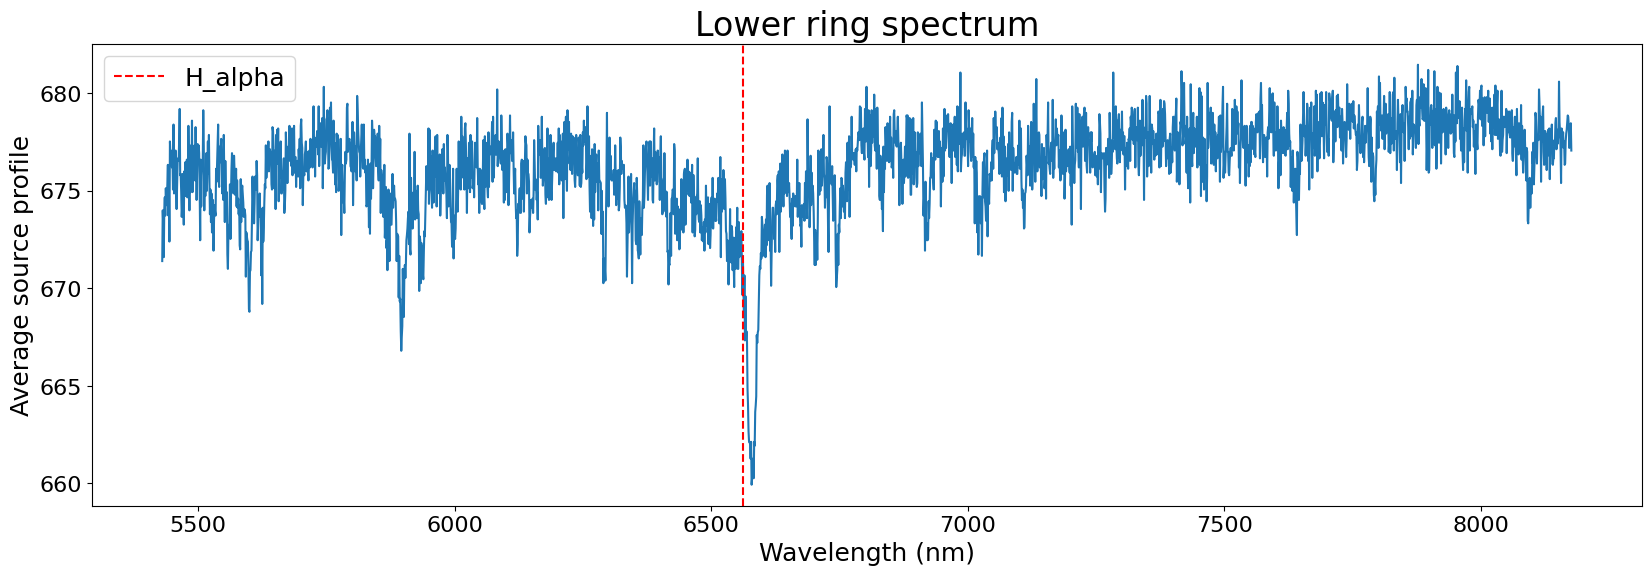

In [ ]:
fig = plt.figure(figsize=(20, 6))
lower_ring_mean_trace_profile = (lower_ring).mean(axis=0)
npixels_to_cut = len(lower_ring_mean_trace_profile)
lower_ring_trace_profile_xaxis =  np.arange(6562.8 - 1133, 6562.8 - 1133 + npixels_to_cut)
plt.plot(lower_ring_trace_profile_xaxis, lower_ring_mean_trace_profile)
plt.title('Lower ring spectrum', fontsize = 24)
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)
plt.axvline(x=6562.8, color='r', linestyle='--', label = 'H_alpha')
plt.legend(fontsize=18)
plt.xlabel("Wavelength (nm)", fontsize = 18 )
plt.ylabel("Average source profile", fontsize = 18);

#Measure Only The Main Part Rotation

In [ ]:
#Divide the main part into three regions
main = cutouts[95:105, ::]
lower = cutouts[60:65, ::]
upper = cutouts[145:150, ::]

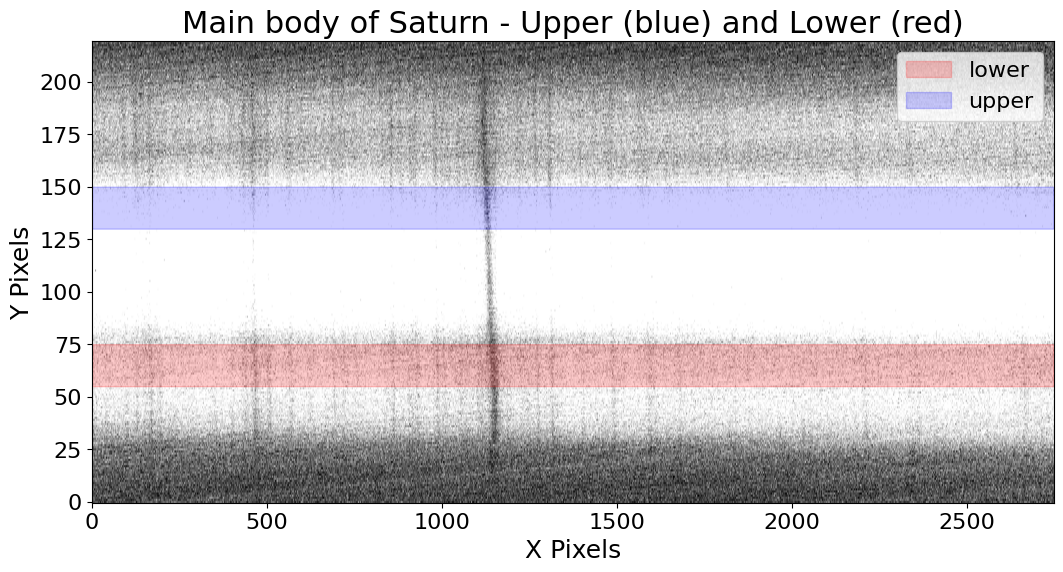

In [ ]:
fig = plt.figure(figsize=(20, 6))
plt.imshow(cutouts, vmin=np.percentile(saturn_img_0,5), vmax=np.percentile(saturn_img_0,95), origin = 'lower', cmap ='gray')
plt.gca().set_aspect(6)
plt.fill_between(
    xvals,
    55,
    75,
    color="red",
    alpha=0.2,
    label='lower'
)


'''
plt.fill_between(
    xvals,
    95,
    105,
    color="green",
    alpha=0.2,
    label='main'
)
'''

plt.fill_between(
    xvals,
    130,
    150,
    color="blue",
    alpha=0.2,
    label='upper'
)


plt.xlabel('X Pixels', fontsize = 18)
plt.ylabel('Y Pixels', fontsize = 18)
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)
plt.title('Main body of Saturn - Upper (blue) and Lower (red)', fontsize = 22)
plt.legend(fontsize=16)
plt.show()


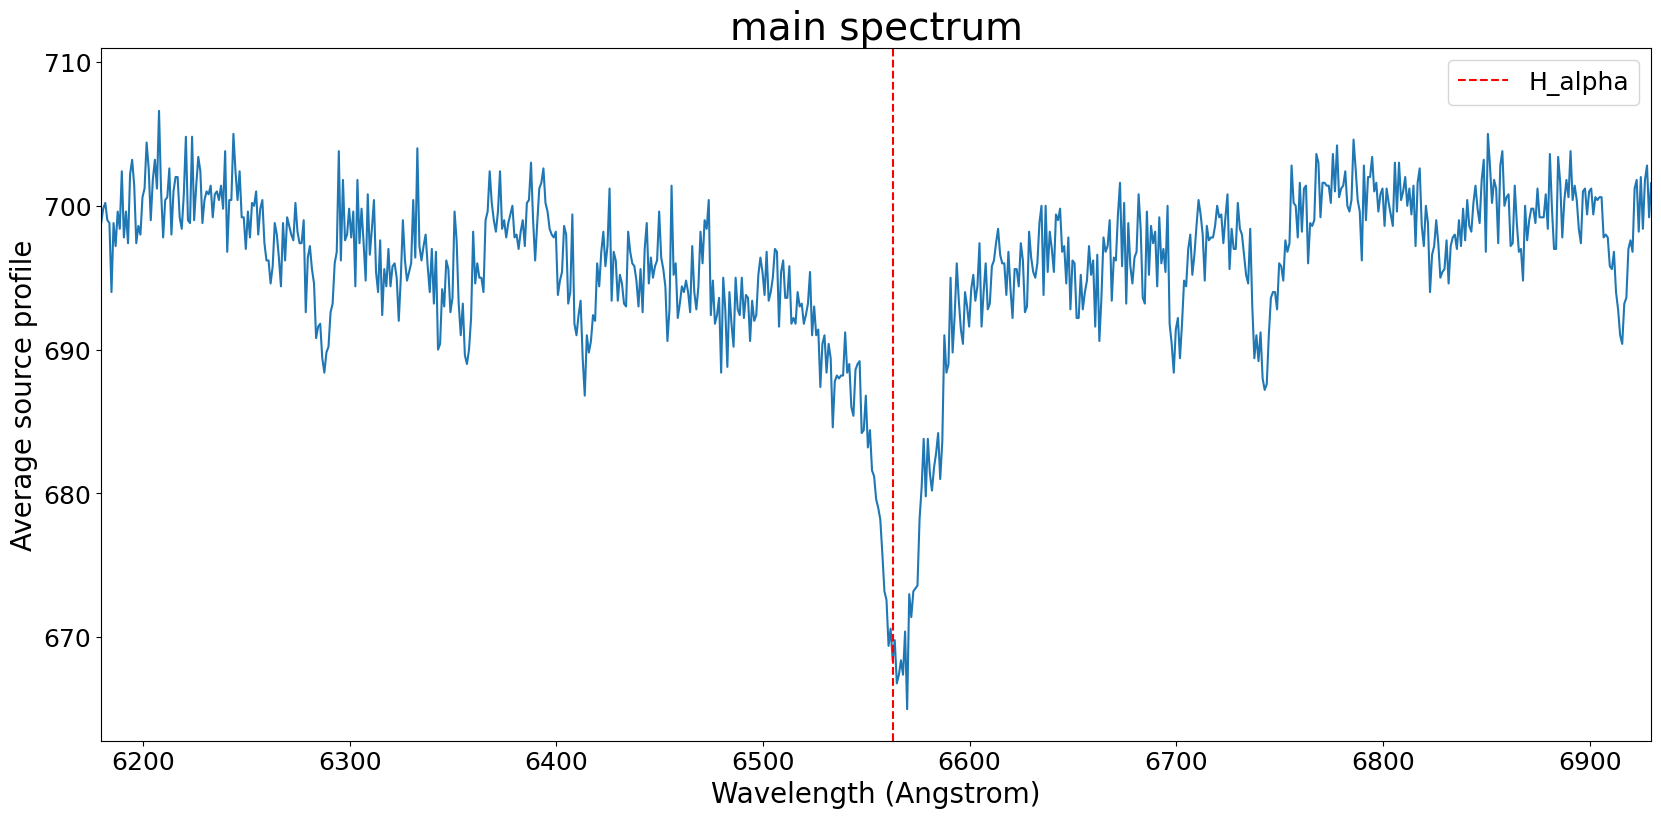

In [ ]:
fig = plt.figure(figsize=(20, 9))
main_mean_trace_profile = (main).mean(axis=0)
npixels_to_cut = len(main_mean_trace_profile)
main_trace_profile_xaxis = np.arange(6562.8 - 1133, 6562.8 - 1133 + npixels_to_cut)
plt.plot(main_trace_profile_xaxis, main_mean_trace_profile)
plt.xlim([750 + 6562.8 - 1133, 1500 + 6562.8 - 1133])
plt.title('main spectrum', fontsize = 28)
plt.xticks(fontsize=18)
plt.yticks(fontsize=18)
#plt.yscale('log')
plt.xlabel("Wavelength (Angstrom)", fontsize = 20)
plt.axvline(x=6562.8, color='r', linestyle='--', label = 'H_alpha')
plt.legend(fontsize=18)
plt.ylabel("Average source profile", fontsize = 20);

In [ ]:
print(min(main_mean_trace_profile))
#extract the x position
print(np.argmin(main_mean_trace_profile))

665.0
1140


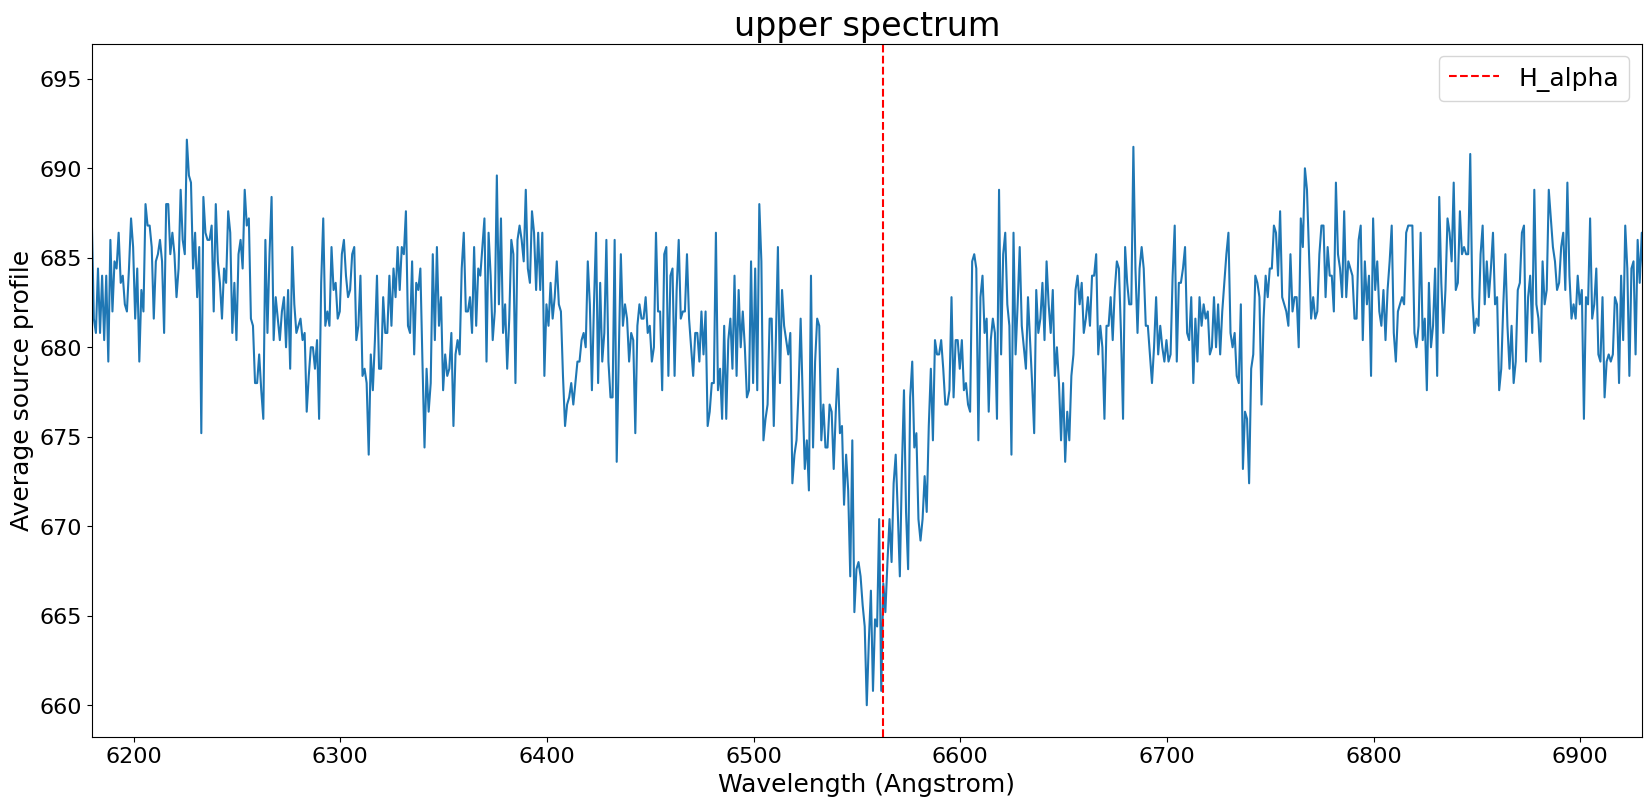

In [ ]:
fig = plt.figure(figsize=(20, 9))
upper_mean_trace_profile = (upper).mean(axis=0)
npixels_to_cut = len(upper_mean_trace_profile)
upper_trace_profile_xaxis = np.arange(6562.8 - 1133, 6562.8 - 1133 + npixels_to_cut)
plt.plot(upper_trace_profile_xaxis, upper_mean_trace_profile)
plt.xlim([750 + 6562.8 - 1133, 1500 + 6562.8 - 1133])
plt.title('upper spectrum', fontsize = 24)
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)
#plt.yscale('log')
plt.xlabel("Wavelength (Angstrom)", fontsize = 18)
plt.axvline(x=6562.8, color='r', linestyle='--', label = 'H_alpha')
plt.legend(fontsize=18)
plt.ylabel("Average source profile", fontsize = 18);

In [ ]:
print(min(upper_mean_trace_profile))
#extract the x position
print(np.argmin(upper_mean_trace_profile))

660.0
1125


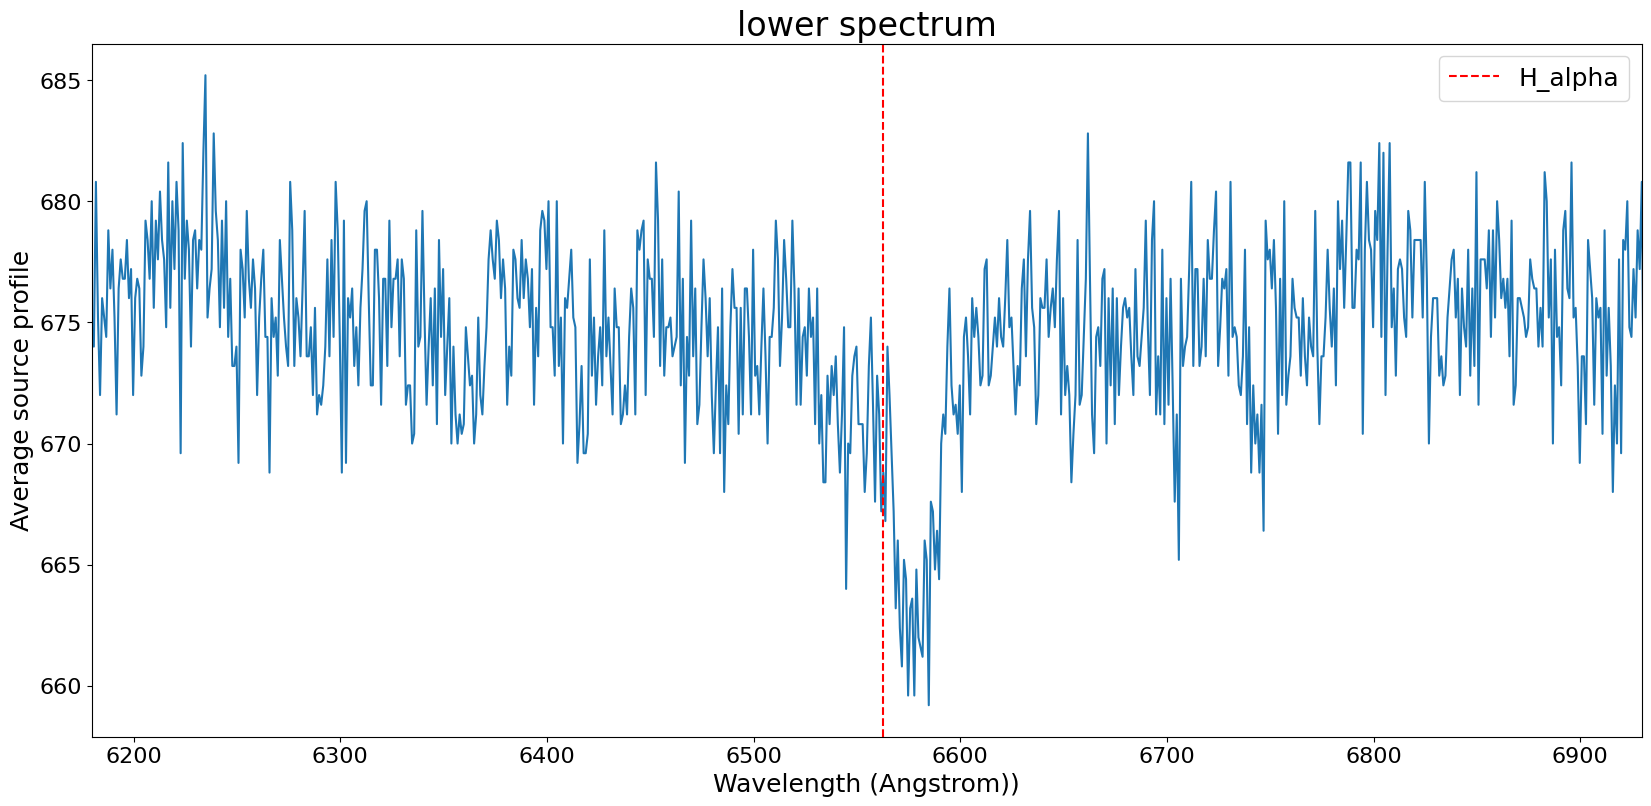

In [ ]:
fig = plt.figure(figsize=(20, 9))
lower_mean_trace_profile = (lower).mean(axis=0)
npixels_to_cut = len(lower_mean_trace_profile)
lower_trace_profile_xaxis = np.arange(6562.8 - 1133, 6562.8 - 1133 + npixels_to_cut)
plt.plot(lower_trace_profile_xaxis, lower_mean_trace_profile)
plt.xlim([750 + 6562.8 - 1133, 1500 + 6562.8 - 1133])
plt.title('lower spectrum', fontsize = 24)
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)
#plt.yscale('log')
plt.xlabel("Wavelength (Angstrom))", fontsize = 18)
plt.axvline(x=6562.8, color='r', linestyle='--', label = 'H_alpha')
plt.legend(fontsize=18)
plt.ylabel("Average source profile", fontsize = 18);

In [ ]:
print(min(lower_mean_trace_profile))
#extract the x position
print(np.argmin(lower_mean_trace_profile))

659.2
1155


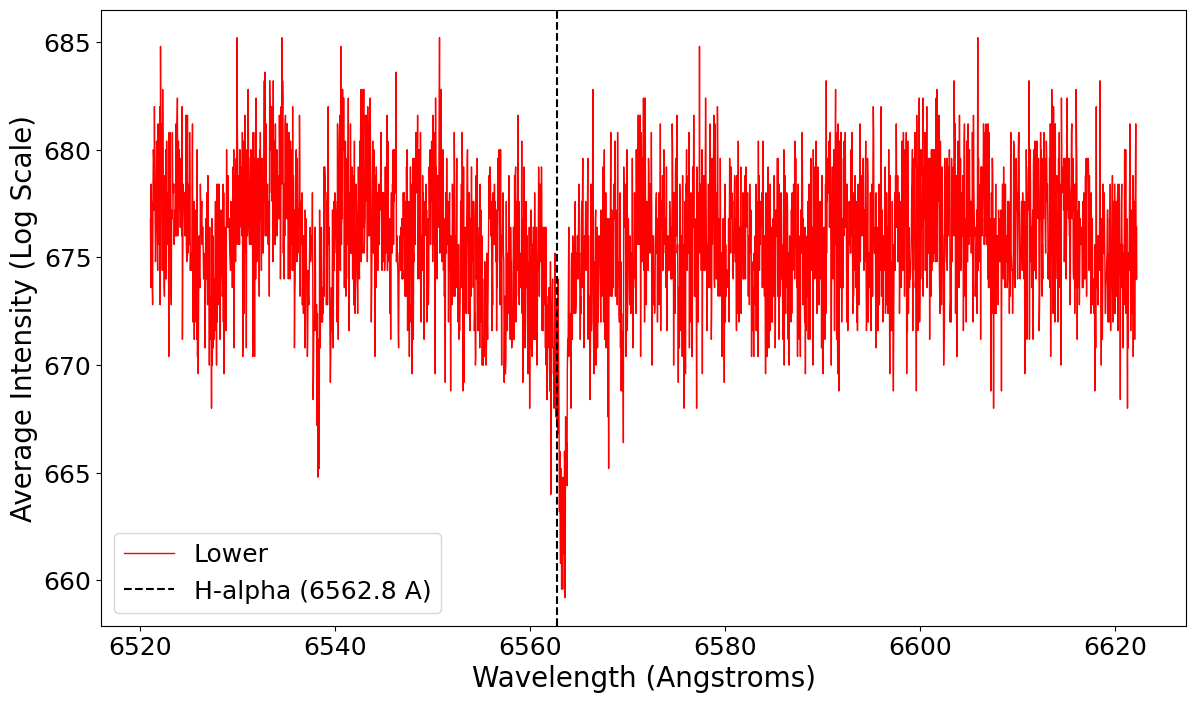

In [ ]:
# Define the anchor point using the H-alpha absorption minimum at index 1140
pixel_anchor = 1133
wavelength_anchor = 6562.8  # H-alpha in Angstroms

# Define the exact dispersion based on the 300 l/mm grating in Littrow configuration
dispersion = 0.0368 # Angstroms/pixel

# Create the calibrated wavelength array
calibrated_wavelength = wavelength_anchor + (xvals - pixel_anchor) * dispersion

# Plot the fully calibrated spectra
fig = plt.figure(figsize=(14, 8))
#plt.title('Calibrated Spectra of Saturn and Rings (300 l/mm Grating)', fontsize=20)

plt.plot(calibrated_wavelength, (lower).mean(axis=0), color='red', label='Lower', linewidth=1.0)
#plt.plot(calibrated_wavelength, (main).mean(axis=0), color='green', label='Main', linewidth=1.5)
#plt.plot(calibrated_wavelength, (upper).mean(axis=0), color='blue', label='Upper', linewidth=1.0)

plt.axvline(x=6562.8, color='black', linestyle='--', label='H-alpha (6562.8 A)')
#plt.xlim([6562.8 - 5.5, 6562.8 + 5.5])  # Zoom out slightly to see the surrounding spectrum
#plt.yscale('log')
plt.xlabel('Wavelength (Angstroms)', fontsize=20)
plt.ylabel('Average Intensity (Log Scale)', fontsize=20)
plt.xticks(fontsize=18)
plt.yticks(fontsize=18)
plt.legend(fontsize=18)
#plt.grid(True, which="both", ls="--")
plt.show()

<Figure size 2000x900 with 0 Axes>

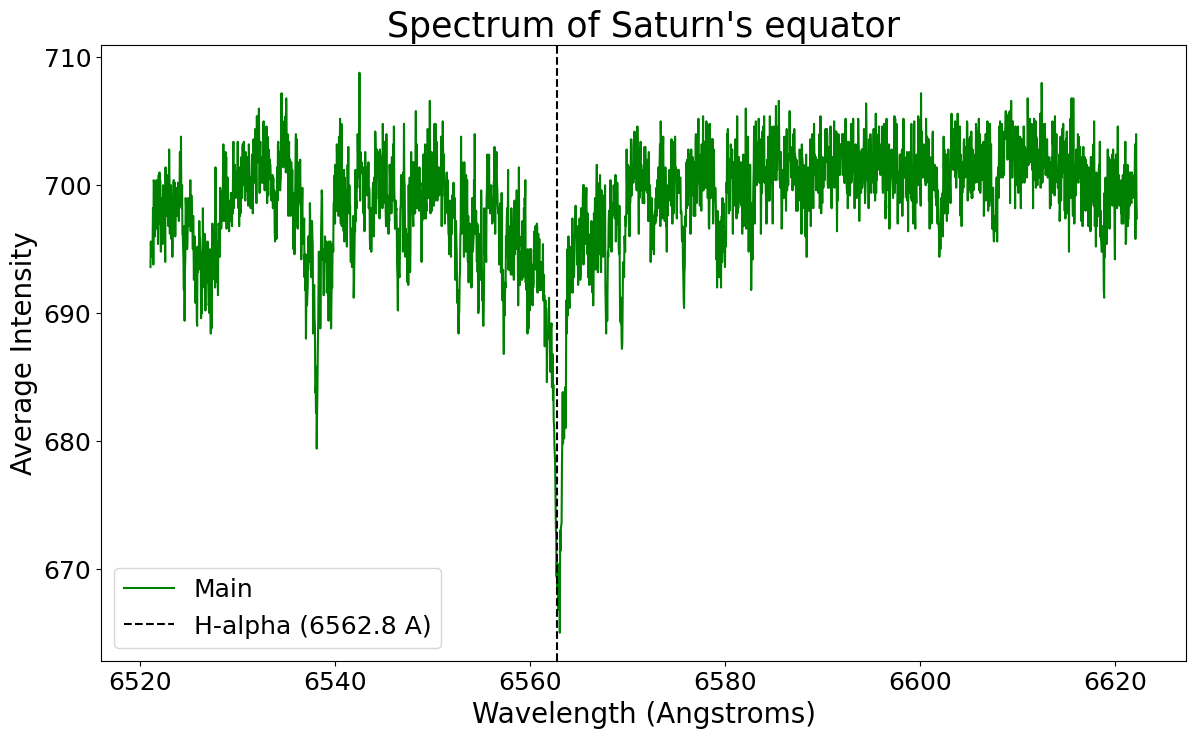

In [ ]:
fig = plt.figure(figsize=(20, 9))

# Define the anchor point using the H-alpha absorption minimum at index 1140
pixel_anchor = 1133
wavelength_anchor = 6562.8  # H-alpha in Angstroms

# Define the exact dispersion based on the 300 l/mm grating in Littrow configuration
dispersion = 0.0368 # Angstroms/pixel

# Create the calibrated wavelength array
calibrated_wavelength = wavelength_anchor + (xvals - pixel_anchor) * dispersion

# Plot the fully calibrated spectra
fig = plt.figure(figsize=(14, 8))
#plt.title('Calibrated Spectra of Saturn and Rings (300 l/mm Grating)', fontsize=20)

#plt.plot(calibrated_wavelength, (lower).mean(axis=0), color='red', label='Lower', linewidth=1.0)
plt.plot(calibrated_wavelength, (main).mean(axis=0), color='green', label='Main', linewidth=1.5)
#plt.plot(calibrated_wavelength, (upper).mean(axis=0), color='blue', label='Upper', linewidth=1.0)

plt.axvline(x=6562.8, color='black', linestyle='--', label='H-alpha (6562.8 A)')
#plt.xlim([6562.8 - 30.5, 6562.8 + 30.5])  # Zoom out slightly to see the surrounding spectrum

plt.xlabel('Wavelength (Angstroms)', fontsize=20)
plt.ylabel('Average Intensity', fontsize=20)
plt.xticks(fontsize=18)
plt.yticks(fontsize=18)
plt.legend(fontsize=18)
plt.title("Spectrum of Saturn's equator", fontsize = 25)
plt.show()

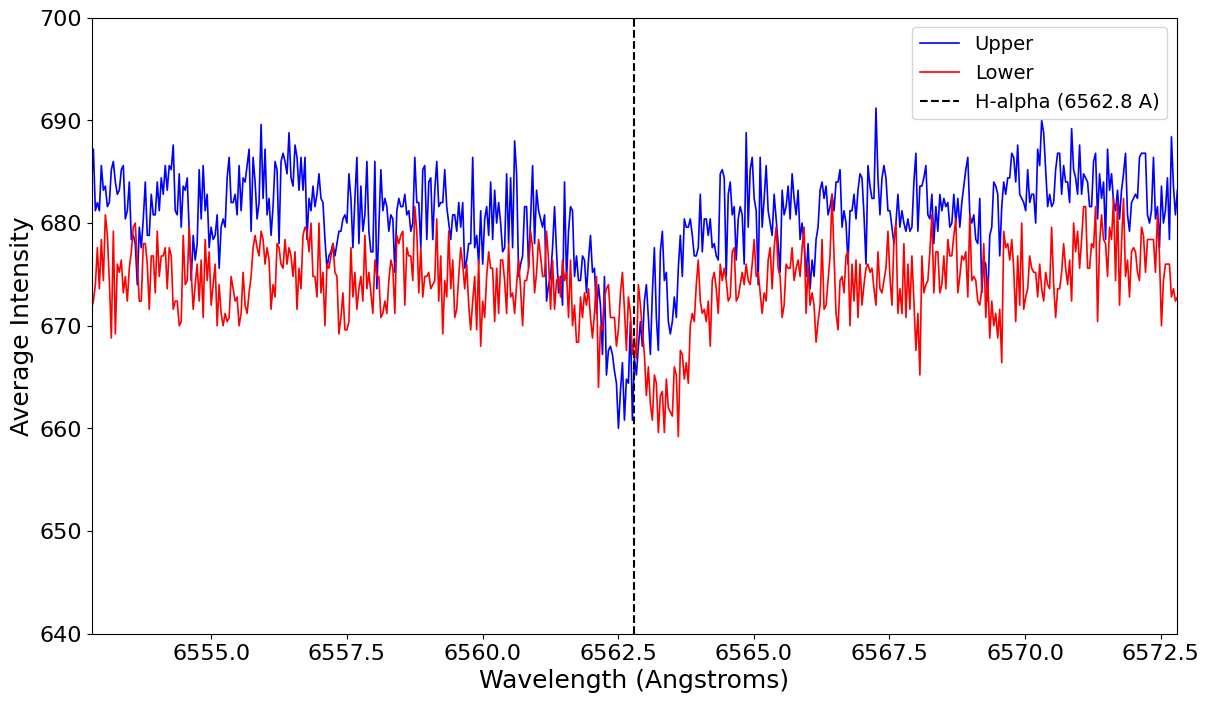

In [ ]:
# Define the anchor point using the H-alpha absorption minimum at index 1140
pixel_anchor = 1133
wavelength_anchor = 6562.8  # H-alpha in Angstroms

# Define the exact dispersion based on the 300 l/mm grating in Littrow configuration
dispersion = 0.0368 # Angstroms/pixel

# Create the calibrated wavelength array
calibrated_wavelength = wavelength_anchor + (xvals - pixel_anchor) * dispersion

# Plot the fully calibrated spectra
fig = plt.figure(figsize=(14, 8))
#plt.title('Calibrated Spectra of Saturn and Rings (300 l/mm Grating)', fontsize=20)

#plt.plot(calibrated_wavelength, (lower).mean(axis=0), color='red', label='Lower', linewidth=1.0)
#plt.plot(calibrated_wavelength, (main).mean(axis=0), color='green', label='Main', linewidth=1.5)
plt.plot(calibrated_wavelength, (upper).mean(axis=0), color='blue', label='Upper', linewidth=1.2)
#plt.plot(calibrated_wavelength, (main).mean(axis=0), color='green', label='Main', linewidth=1.5)
plt.plot(calibrated_wavelength, (lower).mean(axis=0), color='red', label='Lower', linewidth=1.2)

plt.axvline(x=6562.8, color='black', linestyle='--', label='H-alpha (6562.8 A)')
plt.xlim([6562.8 - 10., 6562.8 + 10.])  # Zoom out slightly to see the surrounding spectrum

plt.xlabel('Wavelength (Angstroms)', fontsize=18)
plt.ylabel('Average Intensity', fontsize=18)
plt.legend(fontsize=14)
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)
plt.ylim([640, 700])
#plt.yscale('log')
#plt.grid(True, which="both", ls="--")
plt.show()

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Speed of light in km/s
c_kms = 299792.458
lambda_0 = 6562.8  # Rest wavelength of H-alpha in Angstroms

# Calculate calibrated_wavelength inside this cell
pixel_anchor = 1133
dispersion = 0.0368 # Angstroms/pixel
calibrated_wavelength = lambda_0 + (xvals - pixel_anchor) * dispersion

# Define a function to find the exact absorption minimum by fitting a parabola
# to a small window around the raw minimum (to get sub-pixel precision)
def find_absorption_center(wavelengths, flux, pixel_guess_idx, window_half=10):
    # Extract a small window around the absorption feature
    sub_wave = wavelengths[pixel_guess_idx - window_half : pixel_guess_idx + window_half]
    sub_flux = flux[pixel_guess_idx - window_half : pixel_guess_idx + window_half]

    # Fit a 2nd order polynomial (parabola): y = ax^2 + bx + c
    poly_coeffs = np.polyfit(sub_wave, sub_flux, 2)

    # The minimum of a parabola ax^2 + bx + c is at x = -b / (2a)
    exact_center = -poly_coeffs[1] / (2.0 * poly_coeffs[0])
    return exact_center

def find_absorption_center_robust(wavelengths, flux, pixel_guess_idx, window_half=10):
    n_pixels = len(wavelengths)

    # 1. Prevent negative index wrapping and out-of-bounds errors
    start_idx = max(0, pixel_guess_idx - window_half)
    end_idx = min(n_pixels, pixel_guess_idx + window_half + 1)

    # Ensure the window is large enough to fit a 2nd-order polynomial (needs >= 3 points)
    if (end_idx - start_idx) < 3:
        return np.nan

    sub_wave = wavelengths[start_idx:end_idx]
    sub_flux = flux[start_idx:end_idx]

    # 2. Fit a 2nd order polynomial: y = ax^2 + bx + c
    poly_coeffs = np.polyfit(sub_wave, sub_flux, 2)
    a, b, c = poly_coeffs

    # 3. Check concavity: For an absorption line, 'a' must be positive (concave up)
    if a <= 0:
        # Fallback to the raw minimum index if the fit is inverted or flat
        raw_min_local = np.argmin(sub_flux)
        return sub_wave[raw_min_local]

    # 4. Calculate the vertex of the parabola
    exact_center = -b / (2.0 * a)

    # Ensure the calculated center actually falls within the local fitting window
    if not (sub_wave[0] <= exact_center <= sub_wave[-1]):
        raw_min_local = np.argmin(sub_flux)
        return sub_wave[raw_min_local]

    return exact_center

# We know the absorption pixel minima indexes from previous cells:
# Calculate exact wavelength centers
center_main = find_absorption_center(calibrated_wavelength, main_mean_trace_profile, 1134)
center_upper = find_absorption_center(calibrated_wavelength, upper_mean_trace_profile, 1118)
center_lower = find_absorption_center(calibrated_wavelength, lower_mean_trace_profile, 1143)

center_upper_1 = find_absorption_center_robust(calibrated_wavelength, upper_mean_trace_profile, 1118)
center_lower_1 = find_absorption_center_robust(calibrated_wavelength, lower_mean_trace_profile, 1143)

print(center_lower * dispersion )
print(center_upper * dispersion )

# Calculate Doppler velocities relative to rest wavelength of H-alpha
vel_try_r = 1/4 * c_kms * (center_lower - center_upper) / 6562.8
vel_try_r1 = 1/4 * c_kms * (center_lower_1 - center_upper_1) / 6562.8
vel_r = 1/4 * c_kms * (1143-1118) * dispersion / 6562.8
print(f"Saturn radial speed: {vel_r:+.2f} km/s")
print(f"Saturn radial speed: {vel_try_r:+.2f} km/s")
print(f"Saturn radial speed: {vel_try_r1:+.2f} km/s")
'''
print(f"Measured Line Centers:")
print(f"  Main Body  : {center_main:.3f} Angstroms (Velocity: {vel_main:+.2f} km/s)")
print(f"  Upper Ring : {center_upper:.3f} Angstroms (Velocity: {vel_upper:+.2f} km/s)")
print(f"  Lower Ring : {center_lower:.3f} Angstroms (Velocity: {vel_lower:+.2f} km/s)")

# Calculate relative velocities of the rings with respect to the planet's center
print(f"\nRelative velocities to Saturn's center:")
print(f"  Upper Ring relative speed: {vel_upper - vel_main:+.2f} km/s")
print(f"  Lower Ring relative speed: {vel_lower - vel_main:+.2f} km/s")
'''

241.53471340031135
241.3446244359701
Saturn radial speed: +10.51 km/s
Saturn radial speed: +58.99 km/s
Saturn radial speed: +9.61 km/s


'\nprint(f"Measured Line Centers:")\nprint(f"  Main Body  : {center_main:.3f} Angstroms (Velocity: {vel_main:+.2f} km/s)")\nprint(f"  Upper Ring : {center_upper:.3f} Angstroms (Velocity: {vel_upper:+.2f} km/s)")\nprint(f"  Lower Ring : {center_lower:.3f} Angstroms (Velocity: {vel_lower:+.2f} km/s)")\n\n# Calculate relative velocities of the rings with respect to the planet\'s center\nprint(f"\nRelative velocities to Saturn\'s center:")\nprint(f"  Upper Ring relative speed: {vel_upper - vel_main:+.2f} km/s")\nprint(f"  Lower Ring relative speed: {vel_lower - vel_main:+.2f} km/s")\n'

In [ ]:
import numpy as np
from scipy.optimize import curve_fit

# 1. Define an inverted Gaussian model to fit the absorption line
# y = baseline - amplitude * exp(- (x - mean)**2 / (2 * stddev**2))
def absorption_gaussian(x, baseline, amplitude, mean, stddev):
    return baseline - amplitude * np.exp(-0.5 * ((x - mean) / stddev) ** 2)

def calculate_fwhm(wavelengths, flux, guess_pixel, region_name):
    # Extract a window of +/- 30 pixels around the feature to fit the profile
    window = 20
    x_fit = wavelengths[guess_pixel - window : guess_pixel + window]
    y_fit = flux[guess_pixel - window : guess_pixel + window]

    # Baseline is roughly the maximum flux in this window,
    # depth (amplitude) is baseline - minimum flux
    baseline_guess = np.max(y_fit)
    amplitude_guess = baseline_guess - np.min(y_fit)
    mean_guess = wavelengths[guess_pixel]
    stddev_guess = 1.0  # Initial guess in Angstroms

    p0 = [baseline_guess, amplitude_guess, mean_guess, stddev_guess]

    try:
        popt, _ = curve_fit(absorption_gaussian, x_fit, y_fit, p0=p0)
        baseline, amplitude, mean, stddev = popt

        # FWHM = 2 * sqrt(2 * ln(2)) * stddev approx 2.35482 * stddev
        fwhm = 2.35482 * abs(stddev)

        print(f"{region_name} H-alpha Profile Fit:")
        print(f"  Baseline:   {baseline:.2f}")
        print(f"  Depth:      {amplitude:.2f}")
        print(f"  Center:     {mean:.3f} A")
        print(f"  FWHM:       {fwhm:.3f} A\n")
        return mean, fwhm, popt, x_fit, y_fit
    except Exception as e:
        print(f"Fitting failed for {region_name}: {e}\n")
        return None

# Calculate and display the FWHM for each of our calibrated spectra
# Using estimated pixel indices from the previous analyses
fit_main = calculate_fwhm(calibrated_wavelength, main_mean_trace_profile, 1140, "Main Body (Equator)")
fit_upper = calculate_fwhm(calibrated_wavelength, upper_mean_trace_profile, 1125, "Upper Ring")
fit_lower = calculate_fwhm(calibrated_wavelength, lower_mean_trace_profile, 1155, "Lower Ring")

Main Body (Equator) H-alpha Profile Fit:
  Baseline:   686.12
  Depth:      18.78
  Center:     6562.929 A
  FWHM:       0.674 A

Fitting failed for Upper Ring: Optimal parameters not found: Number of calls to function has reached maxfev = 1000.

Lower Ring H-alpha Profile Fit:
  Baseline:   673.54
  Depth:      12.12
  Center:     6563.368 A
  FWHM:       0.754 A

